<a href="https://colab.research.google.com/github/rafi1624/Machine-Learning_18_Rafi-Abyantara/blob/main/JS08/JS08%20-%20Tugas%20Lab%201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Memuat dan Mempersiapkan Dataset

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv('/content/CC_Customer_Dataset.csv')

# Menampilkan informasi dasar dataset
print("Informasi Dataset:")
display(df.info())
print("\nBeberapa data pertama:")
display(df.head())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


None


Beberapa data pertama:


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


### 2. Prapemrosesan dan Pemodelan Agglomerative Clustering

Kita akan menghapus kolom identifikasi (seperti ID atau sejenisnya jika ada) yang tidak berguna untuk klasterisasi, lalu menstandarkan nilai data agar memiliki skala yang sama.

In [ ]:
# Menentukan fitur yang akan digunakan (mengecualikan kolom non-numerik atau ID jika ada)
# Mari kita periksa kolom yang ada terlebih dahulu dan bersihkan data dari nilai yang hilang
features = df.select_dtypes(include=[np.number]).copy()

# Jika ada kolom ID, kita drop (misal 'Sl_No' atau 'Customer Key' jika ada)
columns_to_drop = [col for col in ['Sl_No', 'Customer Key', 'Customer_Key', 'ID'] if col in features.columns]
features = features.drop(columns=columns_to_drop)

# Mengisi atau menghapus missing values jika ada
features = features.dropna()

# Standarisasi data
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Membuat dan melatih model Agglomerative Clustering
# Kita tentukan jumlah klaster default (misalnya 3, atau Anda bisa menyesuaikannya)
n_clusters = 3
model = AgglomerativeClustering(n_clusters=n_clusters)
labels = model.fit_predict(scaled_features)

# Menambahkan hasil klaster ke dataframe asli
df['Cluster'] = labels
print(f"Model Agglomerative Clustering berhasil dilatih dengan {n_clusters} klaster.")

Model Agglomerative Clustering berhasil dilatih dengan 3 klaster.


### 3. Visualisasi Scatterplot

Visualisasi klaster menggunakan variabel `Avg_Credit_Limit` dan `Total_credit_card`.

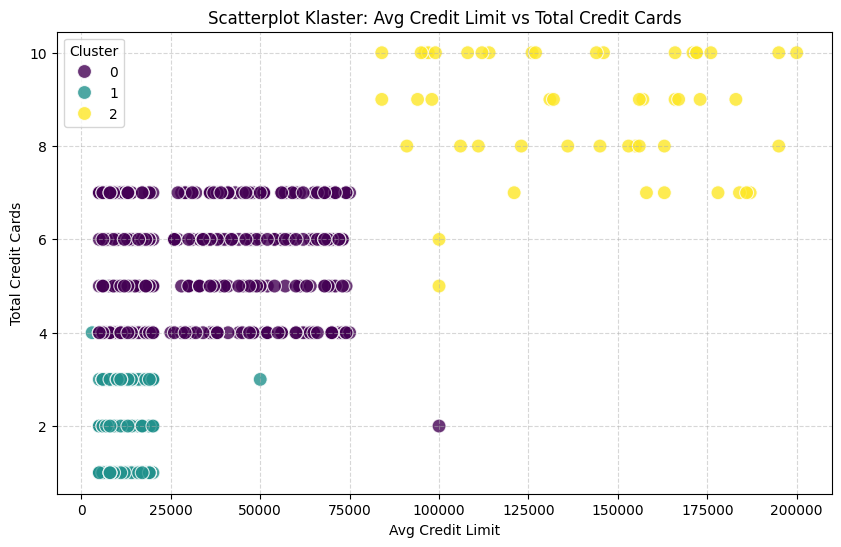

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=df['Avg_Credit_Limit'],
    y=df['Total_Credit_Cards'],
    hue=df['Cluster'],
    palette='viridis',
    s=100,
    alpha=0.8
)
plt.title('Scatterplot Klaster: Avg Credit Limit vs Total Credit Cards')
plt.xlabel('Avg Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 4. Evaluasi Model (Silhouette Score & Davies-Bouldin Index)

In [ ]:
# Menghitung metrik evaluasi berdasarkan fitur yang distandarisasi
sil_score = silhouette_score(scaled_features, labels)
dbi_score = davies_bouldin_score(scaled_features, labels)

print(f"Hasil Evaluasi Model:")
print(f"- Silhouette Score      : {sil_score:.4f}  (Mendekati 1 semakin baik)")
print(f"- Davies-Bouldin Index  : {dbi_score:.4f}  (Semakin kecil semakin baik)")

Hasil Evaluasi Model:
- Silhouette Score      : 0.5148  (Mendekati 1 semakin baik)
- Davies-Bouldin Index  : 0.6810  (Semakin kecil semakin baik)
